In [104]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

#### Carga de datos

In [67]:
df = pd.read_csv("https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+pscomppars&format=csv")

print(df.shape)

(6473, 703)


In [68]:
df = df[["pl_name", # Nombre del exoplaneta
         "hostname", # Nombre de la estrella alrededor de la que orbita
         "pl_rade", # Radio del planeta, expresado en radios terrestres
         "pl_bmasse", # Masa del planeta, expresada en masas terrestres
         "pl_dens", # Densidad del planeta
         "pl_orbper", # Tiempo que tarda el planeta en completar una vuelta alrededor de su estrella, en días
         "pl_orbsmax", # Semieje mayor de su órbita, normalmente expresado en unidades astronómicas (UA)
         "pl_insol", # Cantidad de radiación que recibe el planeta de su estrella, comparada con la que recibe la Tierra del Sol
         "pl_eqt", # Temperatura de equilibrio estimada del planeta, expresada en Kelvin (K)
         "pl_orbeccen", # Excentricidad orbital: indica cuánto se aleja la órbita de una circunferencia perfecta
         "st_teff", # Temperatura efectiva de la estrella, expresada en Kelvin
         "st_lum", # Luminosidad de la estrella, expresada en escala logarítmica respecto al Sol
         "st_rad", # Radio de la estrella, comparado con el radio del Sol
         "st_mass", # Masa de la estrella
         "st_age", # Edad de la estrella
         "st_met", # Metalicidad de la estrella
         "st_logg", # Gravedad superficial de la estrella
         "sy_dist"]] # Distancia desde nuestro sistema solar hasta el sistema planetario, expresada en pársecs (pc)
df

,pl_name,hostname,pl_rade,pl_bmasse,pl_dens,pl_orbper,pl_orbsmax,pl_insol,pl_eqt,pl_orbeccen,st_teff,st_lum,st_rad,st_mass,st_age,st_met,st_logg,sy_dist
0,Kepler-257 d,Kepler-257,4.950000,21.700000,0.983,24.664551,0.160000,15.2000,567.00,0.0000,5180.00,-0.37756,1.0370,0.9160,1.48,0.4000,4.360000,780.2560
1,TOI-1758 b,TOI-1758,3.620000,6.900000,0.830,20.705075,0.141409,21.0500,551.44,0.0000,5169.00,-0.37263,0.8100,0.8800,7.50,-0.0200,4.530000,96.6215
2,Kepler-607 c,Kepler-607,2.760012,8.050000,2.100,39.676800,0.215070,8.8000,473.00,0.0000,5244.00,-0.38192,0.8880,0.8080,7.76,0.0200,4.449000,519.1220
3,Kepler-1040 b,Kepler-1040,2.080000,4.980000,3.040,201.121400,0.672490,2.1210,300.00,0.0000,5694.00,-0.04375,0.9600,0.9800,4.17,0.0100,4.470000,482.1190
4,Kepler-343 b,Kepler-343,2.410000,6.390000,2.510,8.968550,0.088000,206.0720,1024.00,0.0000,5807.00,0.21620,1.4330,1.0550,6.46,0.1445,4.184000,927.1930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6468,TOI-7176 b,TOI-7176,8.653333,200.867553,1.700,47.880000,0.229200,10.0394,376.90,0.1890,4507.00,-0.75203,0.6880,0.7000,9.70,-0.0140,4.608000,69.3535
6469,TOI-6457 b,TOI-6457,10.256217,155.735919,0.790,41.418325,0.251500,1.8988,692.60,0.0000,6171.00,0.38382,1.3590,1.2370,3.00,0.2300,4.264000,263.8070
6470,K2-312 c,HD 80653,12.800000,1681.312273,4.410,871.320000,1.882000,0.4596,229.00,0.8435,5959.00,0.21165,1.1990,1.1500,3.30,0.2550,4.342000,109.8600
6471,ups And b,ups And,14.000000,218.531000,0.438,4.617033,0.059222,955.9835,1523.73,0.0215,6156.77,0.52541,1.5600,1.3000,5.00,0.1014,4.125176,13.4054


In [69]:
print("Dimensiones:", df.shape)

Dimensiones: (6473, 18)


In [ ]:
df = df.dropna(subset=["pl_orbper"])
df = df[df["pl_orbper"] > 0]
df

,pl_name,hostname,pl_rade,pl_bmasse,pl_dens,pl_orbper,pl_orbsmax,pl_insol,pl_eqt,pl_orbeccen,st_teff,st_lum,st_rad,st_mass,st_age,st_met,st_logg,sy_dist
0,Kepler-257 d,Kepler-257,4.950000,21.700000,0.983,24.664551,0.160000,15.2000,567.00,0.0000,5180.00,-0.37756,1.0370,0.9160,1.48,0.4000,4.360000,780.2560
1,TOI-1758 b,TOI-1758,3.620000,6.900000,0.830,20.705075,0.141409,21.0500,551.44,0.0000,5169.00,-0.37263,0.8100,0.8800,7.50,-0.0200,4.530000,96.6215
2,Kepler-607 c,Kepler-607,2.760012,8.050000,2.100,39.676800,0.215070,8.8000,473.00,0.0000,5244.00,-0.38192,0.8880,0.8080,7.76,0.0200,4.449000,519.1220
3,Kepler-1040 b,Kepler-1040,2.080000,4.980000,3.040,201.121400,0.672490,2.1210,300.00,0.0000,5694.00,-0.04375,0.9600,0.9800,4.17,0.0100,4.470000,482.1190
4,Kepler-343 b,Kepler-343,2.410000,6.390000,2.510,8.968550,0.088000,206.0720,1024.00,0.0000,5807.00,0.21620,1.4330,1.0550,6.46,0.1445,4.184000,927.1930
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6468,TOI-7176 b,TOI-7176,8.653333,200.867553,1.700,47.880000,0.229200,10.0394,376.90,0.1890,4507.00,-0.75203,0.6880,0.7000,9.70,-0.0140,4.608000,69.3535
6469,TOI-6457 b,TOI-6457,10.256217,155.735919,0.790,41.418325,0.251500,1.8988,692.60,0.0000,6171.00,0.38382,1.3590,1.2370,3.00,0.2300,4.264000,263.8070
6470,K2-312 c,HD 80653,12.800000,1681.312273,4.410,871.320000,1.882000,0.4596,229.00,0.8435,5959.00,0.21165,1.1990,1.1500,3.30,0.2550,4.342000,109.8600
6471,ups And b,ups And,14.000000,218.531000,0.438,4.617033,0.059222,955.9835,1523.73,0.0215,6156.77,0.52541,1.5600,1.3000,5.00,0.1014,4.125176,13.4054


In [71]:
df["short_orbit"] = (df["pl_orbper"] <= 10).astype(int)

#### Comprobaciones antes de entrenar y EDA

In [74]:
df["short_orbit"].value_counts()

#df["habitability_class"].value_counts()

short_orbit
0    3168
1    2947
Name: count, dtype: int64

In [ ]:
df["short_orbit"].value_counts(normalize=True)*100

short_orbit
0    51.807032
1    48.192968
Name: proportion, dtype: float64

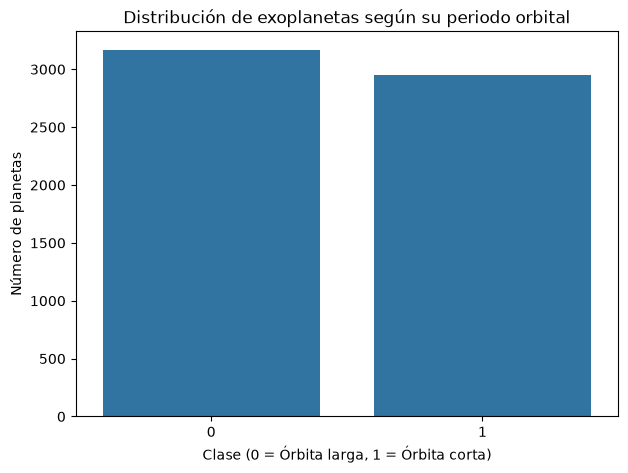

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="short_orbit")

plt.title("Distribución de exoplanetas según su periodo orbital")
plt.xlabel("Clase (0 = Órbita larga, 1 = Órbita corta)")
plt.ylabel("Número de planetas")

plt.show()

In [77]:
df.info()

<class 'pandas.DataFrame'>
Index: 6115 entries, 0 to 6472
Data columns (total 19 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   pl_name      6115 non-null   str    
 1   hostname     6115 non-null   str    
 2   pl_rade      6068 non-null   float64
 3   pl_bmasse    6087 non-null   float64
 4   pl_dens      5973 non-null   float64
 5   pl_orbper    6115 non-null   float64
 6   pl_orbsmax   5623 non-null   float64
 7   pl_insol     5814 non-null   float64
 8   pl_eqt       5861 non-null   float64
 9   pl_orbeccen  5392 non-null   float64
 10  st_teff      6090 non-null   float64
 11  st_lum       6081 non-null   float64
 12  st_rad       6076 non-null   float64
 13  st_mass      6114 non-null   float64
 14  st_age       4876 non-null   float64
 15  st_met       5746 non-null   float64
 16  st_logg      6072 non-null   float64
 17  sy_dist      6093 non-null   float64
 18  short_orbit  6115 non-null   int64  
dtypes: float64(16), int64(

In [78]:
df.describe()

,pl_rade,pl_bmasse,pl_dens,pl_orbper,pl_orbsmax,pl_insol,pl_eqt,pl_orbeccen,st_teff,st_lum,st_rad,st_mass,st_age,st_met,st_logg,sy_dist,short_orbit
count,6068.000000,6087.000000,5973.000000,6.115000e+03,5623.000000,5814.000000,5861.000000,5392.000000,6090.000000,6081.000000,6076.000000,6114.000000,4876.000000,5746.000000,6072.000000,6093.000000,6115.000000
mean,5.540650,339.271249,4.850966,7.001434e+04,2.195971,533.055021,833.574115,0.078955,5390.503345,-0.146248,1.484205,0.954860,4.448366,0.016946,4.385262,484.686432,0.481930
std,5.117028,1017.589547,34.665693,5.143173e+06,100.583839,9886.545275,486.722163,0.152199,1693.569066,0.772335,3.845462,0.354642,2.990270,0.188174,0.435496,521.960162,0.499714
min,0.309800,0.020000,0.005100,9.070629e-02,0.004400,0.000000,24.390000,0.000000,415.000000,-4.660000,0.011500,0.013100,0.000000,-1.000000,0.541000,1.301190,0.000000
25%,1.800000,4.125000,1.340000,4.288576e+00,0.050729,10.861475,488.000000,0.000000,4909.000000,-0.474890,0.770000,0.798000,2.400000,-0.080000,4.292000,92.383100,0.000000
50%,2.756025,8.696790,2.540000,1.064026e+01,0.094000,68.487350,757.000000,0.000000,5549.000000,-0.076320,0.950000,0.950000,4.000000,0.020000,4.455500,330.575000,0.000000
75%,10.892500,146.649448,4.540000,3.804050e+01,0.232275,287.900000,1090.000000,0.090000,5900.000000,0.309120,1.245000,1.095750,5.760000,0.130000,4.580000,756.742000,1.000000
max,29.330000,12651.500000,2000.000000,4.020000e+08,7506.000000,636352.125800,7777.780000,0.950000,57000.000000,3.260760,88.475000,8.760000,16.100000,0.790000,8.070000,8500.000000,1.000000


In [79]:
df.isnull().sum().sort_values(ascending=False)

st_age         1239
pl_orbeccen     723
pl_orbsmax      492
st_met          369
pl_insol        301
pl_eqt          254
pl_dens         142
pl_rade          47
st_logg          43
st_rad           39
st_lum           34
pl_bmasse        28
st_teff          25
sy_dist          22
st_mass           1
hostname          0
pl_name           0
pl_orbper         0
short_orbit       0
dtype: int64

In [80]:
(df.isnull().mean()*100).sort_values(ascending=False)

st_age         20.261652
pl_orbeccen    11.823385
pl_orbsmax      8.045789
st_met          6.034342
pl_insol        4.922322
pl_eqt          4.153720
pl_dens         2.322159
pl_rade         0.768602
st_logg         0.703189
st_rad          0.637776
st_lum          0.556010
pl_bmasse       0.457890
st_teff         0.408831
sy_dist         0.359771
st_mass         0.016353
hostname        0.000000
pl_name         0.000000
pl_orbper       0.000000
short_orbit     0.000000
dtype: float64

In [ ]:
features = ["pl_rade","pl_bmasse","pl_dens","pl_orbeccen","st_teff","st_lum","st_rad","st_mass","st_age","st_met","st_logg","sy_dist"]

X = df[features]

y = df["short_orbit"]

In [ ]:
print("Número de planetas por clase:")
print(y.value_counts())

print("\nPorcentaje por clase:")
print(y.value_counts(normalize=True)*100)

Número de planetas por clase:
short_orbit
0    3168
1    2947
Name: count, dtype: int64

Porcentaje por clase:
short_orbit
0    51.807032
1    48.192968
Name: proportion, dtype: float64


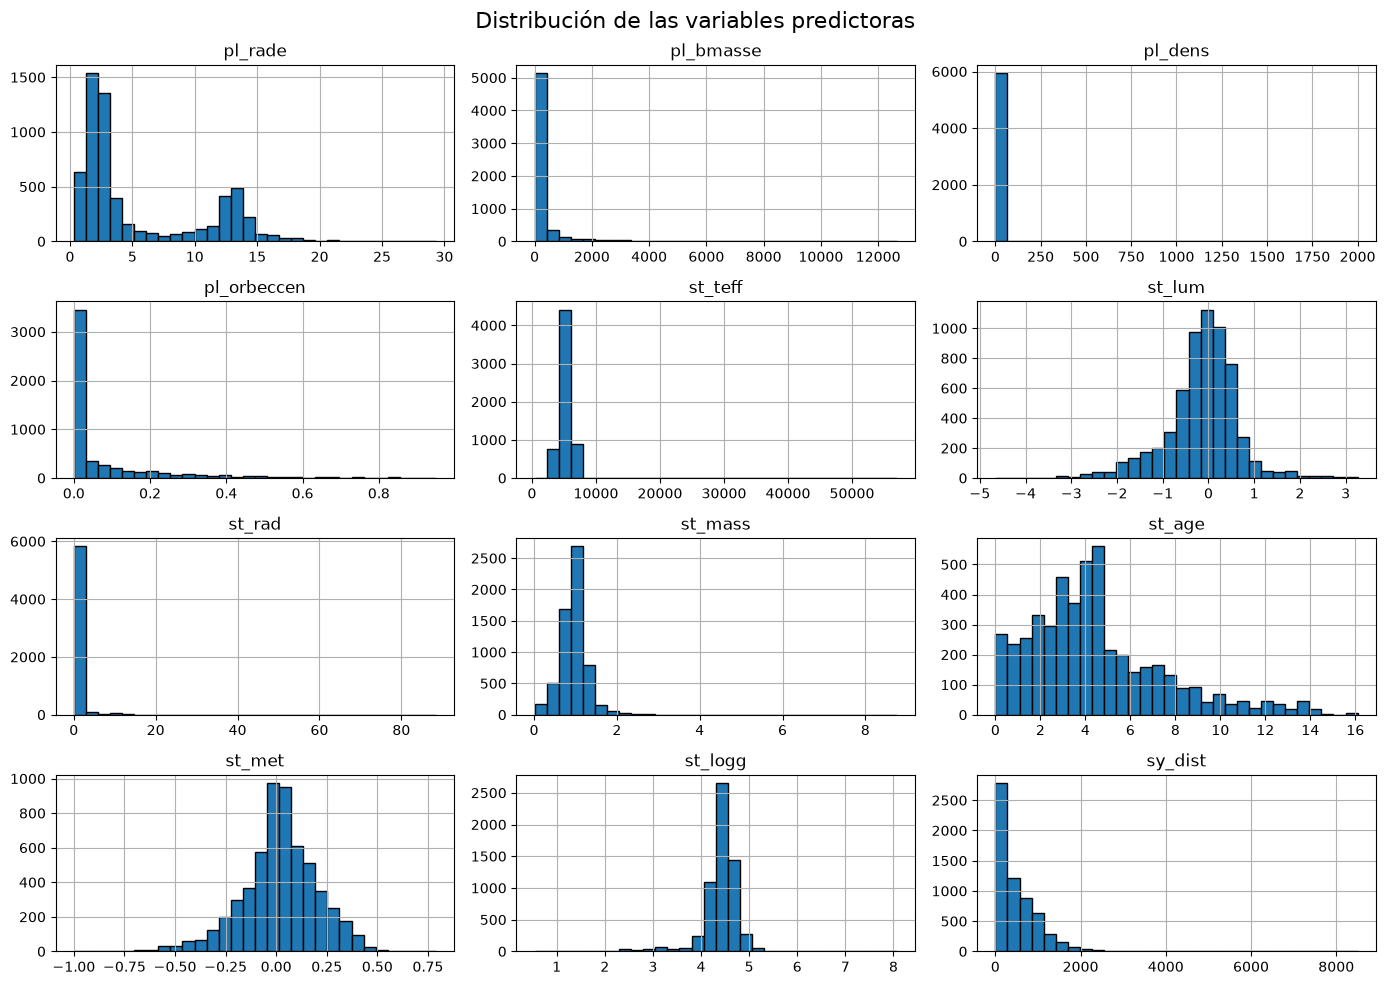

In [ ]:
X.hist(figsize=(14, 10), bins=30, edgecolor="black")

plt.suptitle("Distribución de las variables predictoras", fontsize=16)

plt.tight_layout()
plt.show()

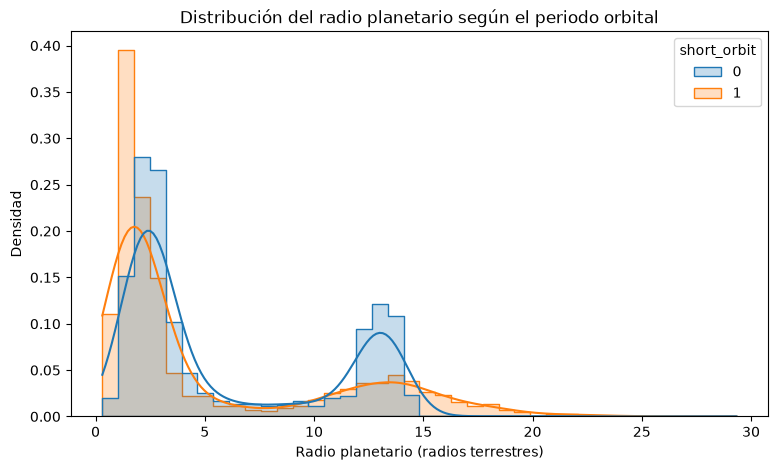

In [84]:
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x="pl_rade", hue="short_orbit", bins=40, kde=True, element="step", stat="density", common_norm=False)

plt.title("Distribución del radio planetario según el periodo orbital")
plt.xlabel("Radio planetario (radios terrestres)")
plt.ylabel("Densidad")

plt.show()

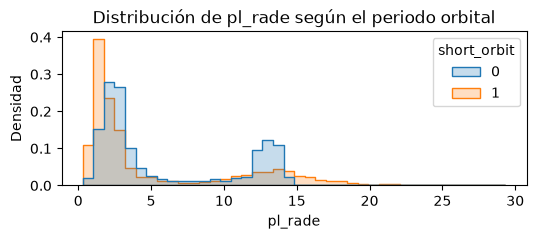

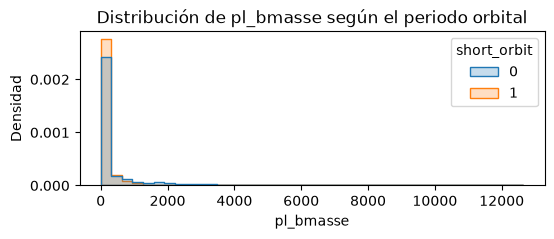

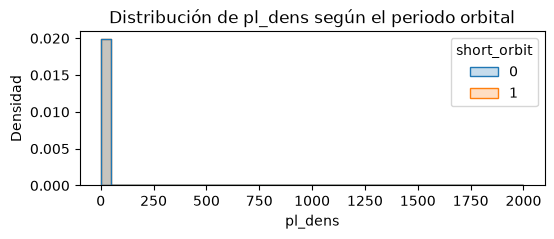

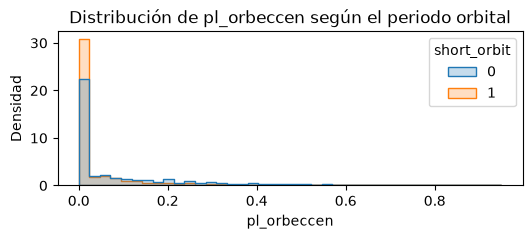

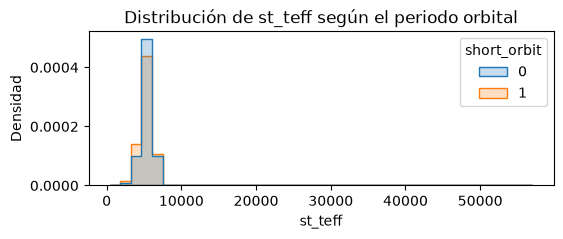

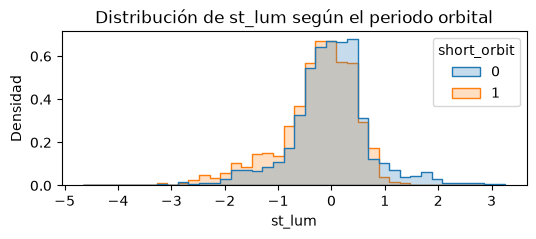

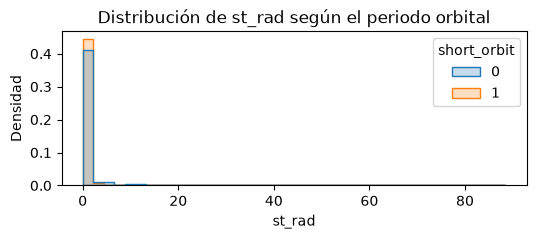

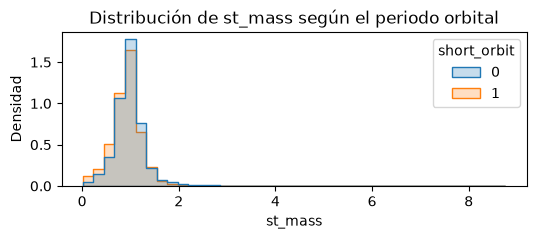

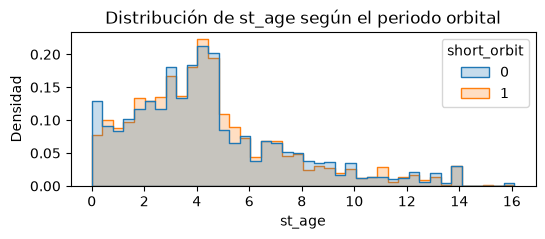

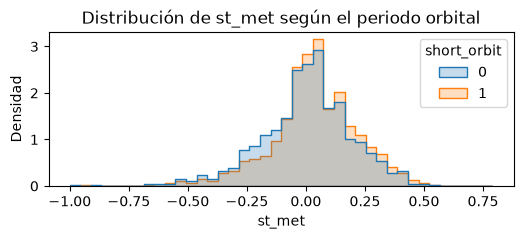

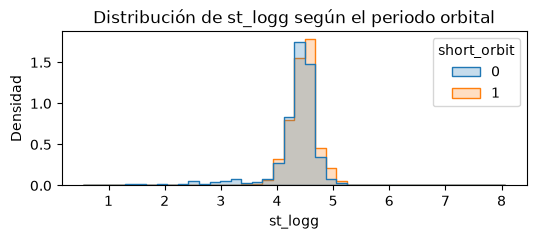

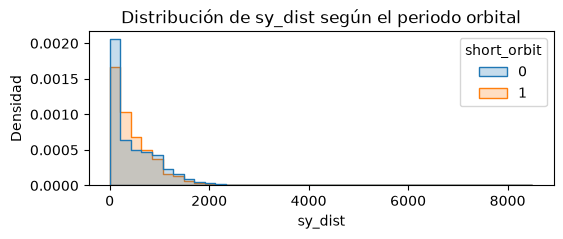

In [94]:
for col in features:

    plt.figure(figsize=(6, 2))

    sns.histplot(data=df, x=col, hue="short_orbit", bins=40, element="step", stat="density", common_norm=False)

    plt.title(f"Distribución de {col} según el periodo orbital")
    plt.xlabel(col)
    plt.ylabel("Densidad")

    plt.show()

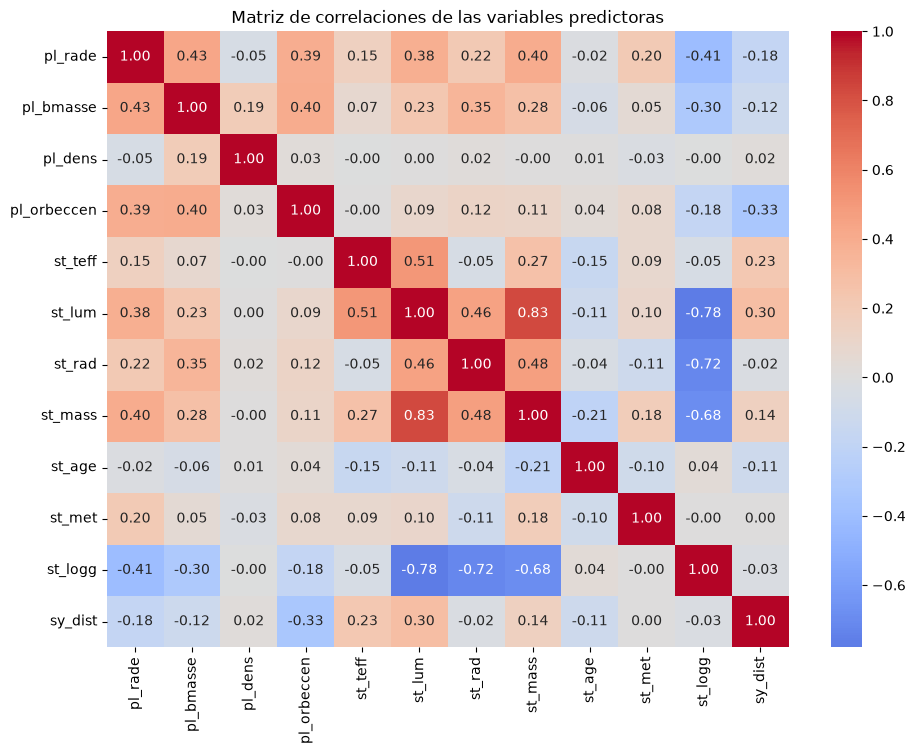

In [ ]:
plt.figure(figsize=(11, 8))

correlacion = X.corr()

sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f",center=0)

plt.title("Matriz de correlaciones de las variables predictoras")

plt.show()

#### División de los datos en test y train, y entrenamiento

In [92]:
print("Número de planetas:", len(df))

print("Número de estrellas diferentes:", df["hostname"].nunique())

print("Número de estrellas con varios planetas:")
print((df["hostname"].value_counts() > 1).sum())

Número de planetas: 6115
Número de estrellas diferentes: 4521
Número de estrellas con varios planetas:
1059


In [ ]:
# Normalmente se podría utilizar train_test_split, pero aquí hay una particularidad: varios planetas pueden pertenecer a la misma estrella.
# Por ejemplo, si hiciéramos una división normal podría ocurrir que algunos planetas de Kepler-11 estuvieran en entrenamiento y otros en test.
# Si pasara eso, el modelo podría aprovechar información de una estrella que ya ha visto; por ello usamos StratifiedGroupKFold.

# Stratified -> mantiene la proporción de las clases en los diferentes conjuntos. Las clases son short_orbit (0 o 1)
# Group -> mantiene juntos los registros que pertenecen al mismo grupo. Los grupos son las estrellas (hostname)

groups = df["hostname"]

sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

# split() analiza X, y, gropus y genera cinco divisiones diferentes.
# split() genera las cinco particiones de forma iterativa, va proporcionando una división cada vez.
#   next() obtiene únicamente la primera división generada.
# train_idx y test_idx contiene los índices de las filas que pertenecen a cada conjunto.
train_idx, test_idx = next(sgkf.split(X, y, groups))

# Obtenemos las filas a partir de los índices de antes
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# Sacamos las estrellas (hostname) de los planetas de train y test
groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

In [97]:
print("Entrenamiento:", X_train.shape)
print("Test:", X_test.shape)

Entrenamiento: (4892, 12)
Test: (1223, 12)


In [ ]:
print("Porcentaje en entrenamiento:")
print(y_train.value_counts(normalize=True)*100)

print("\nPorcentaje en test:")
print(y_test.value_counts(normalize=True)*100)

Porcentaje en entrenamiento:
short_orbit
0    51.798855
1    48.201145
Name: proportion, dtype: float64

Porcentaje en test:
short_orbit
0    51.839738
1    48.160262
Name: proportion, dtype: float64


In [99]:
estrellas_compartidas = set(groups_train) & set(groups_test)

print("Estrellas compartidas:", len(estrellas_compartidas))

Estrellas compartidas: 0


#### Manejo de valores nulos (imputaciones)

In [101]:
nulos = X_train.isnull().sum().sort_values(ascending=False)
print(nulos)

st_age         991
pl_orbeccen    583
st_met         293
pl_dens        115
pl_rade         41
st_logg         35
st_rad          32
st_lum          27
pl_bmasse       20
st_teff         19
sy_dist         19
st_mass          0
dtype: int64


In [102]:
porcentaje_nulos = (X_train.isnull().mean()*100).sort_values(ascending=False)
print(porcentaje_nulos)

st_age         20.257563
pl_orbeccen    11.917416
st_met          5.989370
pl_dens         2.350777
pl_rade         0.838103
st_logg         0.715454
st_rad          0.654129
st_lum          0.551922
pl_bmasse       0.408831
st_teff         0.388389
sy_dist         0.388389
st_mass         0.000000
dtype: float64


In [ ]:
# Imputador KNN
# Busca los vecinos más próximos teniendo en cuenta las características de cada observación y utiliza sus valores para estimar los ausentes.
#   Usaremos 5 vecinos.
pipe_knn = Pipeline([("scaler", StandardScaler()), ("imputer", KNNImputer(n_neighbors=5))])

# Imputador Iterativo
# Estima los valores ausentes mediante modelos predictivos iterativos. 
#   En cada iteración utiliza el resto de variables para predecir una variable que contiene valores ausentes. Usaremos 10 iteraciones.
pipe_iterative = Pipeline([("scaler", StandardScaler()), ("imputer", IterativeImputer(random_state=42, max_iter=10, tol=0.001))])